[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZacharyHillman18/PharmapyWorkshop/blob/main/Workshop_Challenges/solutions/Challenge2_CrystallizerDesign_solution.ipynb)

In [1]:
# Solution notebooks live in solutions/. They run from the parent folder,
# where data/ and workshop_utils.py are. (This cell is not in the student version.)
import os
import sys

if os.path.basename(os.getcwd()) == 'solutions':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

# Challenge 2: Shaping the crystal size distribution

Each part of this notebook has a different level of guidance:

1. **Example**: fully worked. Run it and read it; it shows all the PharmaPy syntax you will need.
2. **Guided**: fill in the lines marked `# <-- COMPLETE THIS`.
3. **Unguided**: you get the task, the math and the syntax of the PharmaPy pieces; you write the code.

The plotting helpers in `workshop_utils.py` are given, so that everyone's figures look the same and results are easy to compare. The [SyntaxExamples notebook](https://colab.research.google.com/github/ZacharyHillman18/PharmapyWorkshop/blob/main/Workshop_Challenges/SyntaxExamples.ipynb) has small runnable examples of every PharmaPy object.

Rough timing: Example 10 min, Guided 12 min, Unguided 20 min, questions 8 min.

## The system

Compound **C** crystallizes from a 20 wt% solution in a seeded batch cooling crystallizer: 1 kg of solution is seeded at $T_0$ = 293.15 K, cooled to $T_f$ = 273.15 K in 120 min and held for 30 min. The population balance (size-independent growth) is

$$ \frac{\partial n}{\partial t} + G \frac{\partial n}{\partial L} = 0, \qquad n(L_0, t) = \frac{B}{G}, \qquad B = k_b S^b, \qquad G = k_g S^g, \qquad S = \frac{c - c^*(T)}{c^*(T)} $$

PharmaPy solves it with the finite-volume method on a size grid, which gives the full crystal size distribution (CSD). Note that $b \approx 8.3$ is much larger than $g \approx 4.5$: high supersaturation favors nucleation (many small crystals) over growth.

The final temperature fixes how much C crystallizes (the yield), so **the only freedom is how we get there**: the temperature profile and the seeds. The product quality is measured on the volume-weighted CSD: the median size $d_{50}$ and the width

$$ \mathrm{span} = \frac{d_{90} - d_{10}}{d_{50}} $$

**Running on Google Colab?** Run the next cell first. It installs PharmaPy and puts this notebook's data files and `workshop_utils.py` on the Colab machine (about half a minute). Run it again whenever the runtime restarts. To keep your work, use *File → Save a copy in Drive*. On your own computer the cell skips the install and only unpacks the files.

In [ ]:
# @title Colab setup: run this cell first { display-mode: "form" }
# Installs PharmaPy and unpacks workshop_utils.py and data/ into the working
# directory. Run it again after a runtime restart or a factory reset.
import base64, importlib.metadata, importlib.util, io, os, subprocess, sys, zipfile

if 'google.colab' in sys.modules or importlib.util.find_spec('PharmaPy') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pharmapy-org>=0.3.1'], check=True)

_FILES = (
    '...'
)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_FILES))) as archive:
    archive.extractall('.')
importlib.invalidate_caches()

try:
    _version = importlib.metadata.version('pharmapy-org')
except importlib.metadata.PackageNotFoundError:   # a development install of PharmaPy
    _version = '(development install)'
print('PharmaPy', _version, '- workshop files ready in', os.getcwd())

## Setup (given)

`cryst_kinetics()` returns a **new** kinetics object each time (every crystallizer needs its own). Its argument `kg_factor` multiplies the growth rate constant; you need it only in the questions at the end.

Your PharmaPy version needs no workshop fixes.


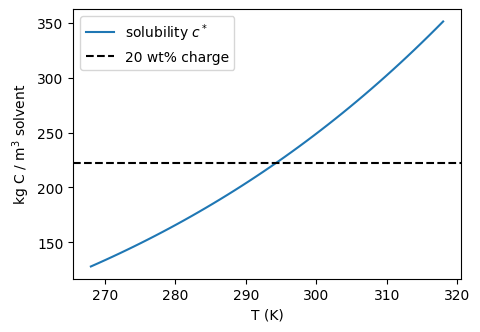

In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar

from PharmaPy.Phases_Refactored import LiquidPhase, SolidPhase
from PharmaPy.Crystallizers_Refactored import BatchCrystallizer
from PharmaPy.Mechanisms import OneDFVMMechanism
from PharmaPy.Kinetics import CrystKinetics
from PharmaPy.ProcessControl_Refactored import SimpleTemperatureController
from PharmaPy.IntegratorBackends import ScipyBackend

from workshop_utils import apply_pharmapy_patches, csd_quantiles, plot_batches, plot_profiles

apply_pharmapy_patches()

path = 'data/compounds_workshop.json'   # species: A, B, C, D, solvent

# Kinetics of C (from PharmaPy's crystTester.py)
SOLUB_COEFFS = np.array([-28.13909202, 0.001, 5.900800253])   # Apelblat: c* = exp(a1 + a2/T + a3 ln T), kg C / m3 solvent
NUCL_PRIM = (1.0448e17, 0, 8.30671806)   # (k_b, E_b, b): primary nucleation, #/(m3 s)
GROWTH = (2.4297e4, 0, 4.52241037)        # (k_g, E_g, g): growth, um/s
NO_SECONDARY = (0, 0, 0, 0)               # (k_s, E_s, s1, s2): secondary nucleation, switched off


def cryst_kinetics(kg_factor=1.0, nucl_sec=NO_SECONDARY):
    growth = (GROWTH[0] * kg_factor,) + GROWTH[1:]
    return CrystKinetics(SOLUB_COEFFS, nucl_prim=NUCL_PRIM, nucl_sec=nucl_sec, growth=growth,
                         solubility_type='apelblat', solubility_basis='mass_per_volume_solvent')


# Operation
W_C = 0.2                            # mass fraction of C in the charge
MASS = 1.0                           # kg of solution
T0, TF = 293.15, 273.15              # K: seeding and final temperature
T_COOL, T_HOLD = 120 * 60, 30 * 60   # s: cooling time and final hold
TIME_GRID = np.linspace(0, T_COOL + T_HOLD, 61)   # s, output times

# Population balance: size grid and seeds
X_GRID = np.geomspace(1, 1500, 40)   # um
SEED_SIZE = 100                      # um


def seed_shape():
    """Volume-fraction shape of the seeds on X_GRID (log-normal around SEED_SIZE)."""
    return np.exp(-0.5 * (np.log(X_GRID / SEED_SIZE) / 0.15)**2)


temps = np.linspace(268, 318, 50)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(temps, [cryst_kinetics().get_solubility(T) for T in temps], label='solubility $c^*$')
ax.axhline(W_C / (1 - W_C) * 887.6, color='k', ls='--', label='20 wt% charge')   # 887.6 kg/m3: solvent density
ax.set_xlabel('T (K)')
ax.set_ylabel('kg C / m$^3$ solvent')
ax.legend()
plt.show()

---
# Part 1 — Example: a seeded batch with linear cooling

A crystallizer is assembled like any PharmaPy unit:

1. the **unit** with its own integrator and, here, a **controller** that prescribes the temperature: `SimpleTemperatureController(temp_func=f)`, where `f(t)` returns the temperature (K) at time `t` (s);
2. the **phases**: the liquid charge and a solid phase of C. The solid carries the population balance as a **mechanism**, attached *before* the solid goes into the crystallizer. `OneDFVMMechanism` discretizes the CSD on `x_grid`; seeds are given as a volume-fraction shape plus their mass (`distrib_basis='vol_perc'`);
3. the **kinetics**, attached after the phases;
4. `solve_unit(...)`.

The seed loading is 1 % of the dissolved C: little enough that nucleation still competes with growth, so the temperature profile matters.

In [3]:
temp_linear = lambda t: np.interp(t, [0, T_COOL], [T0, TF])    # K; np.interp holds TF after T_COOL

cryst = BatchCrystallizer(integrator=ScipyBackend(options={'maxh': 60}),
                          controller=SimpleTemperatureController(temp_func=temp_linear))

liquid = LiquidPhase(path, temp=T0, mass=MASS, mass_frac=[0, 0, W_C, 0, 1 - W_C], name_solv='solvent')
solid = SolidPhase(path, temp=T0, mass=0, mass_frac=[0, 0, 1, 0, 0])

seed_mass = 0.01 * W_C * MASS      # kg: 1 % of the dissolved C
solid.mechanisms = OneDFVMMechanism(solid, target_components='C', solvent_name='solvent',
                                    x_grid=X_GRID, distrib_init=seed_shape(),
                                    distrib_basis='vol_perc', basis_mass=seed_mass, vol_slurry=liquid.vol)

cryst.Phases = [liquid, solid]
cryst.CrystKinetics = cryst_kinetics()

tic = time.perf_counter()
cryst.solve_unit(time_grid=TIME_GRID, verbose=False)
print('simulation time: %.1f s' % (time.perf_counter() - tic))

simulation time: 1.9 s


### Reading the CSD

The final distribution is a number density (#/($\mu$m m$^3$)) on the grid of the mechanism. `csd_quantiles` turns it into the volume-weighted $d_{10}$, $d_{50}$, $d_{90}$ and span. `plot_batches` (given) plots the temperature, the supersaturation and the final CSD of one or more runs.

{'d10': np.float64(114.45), 'd50': np.float64(221.16), 'd90': np.float64(317.94), 'span': np.float64(0.92)}


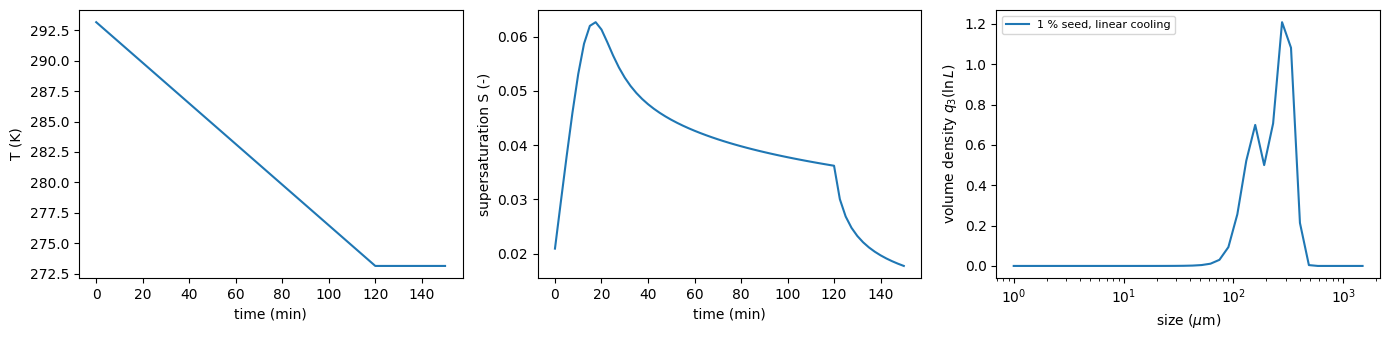

In [4]:
mech = cryst.Phases.Solids[0].mechanisms[0]        # the population balance of the first solid phase
distrib_end = cryst.result.distrib_solid0[-1]       # number density at the final time
print({key: round(val, 2) for key, val in csd_quantiles(mech.x_grid, distrib_end, mech.dx).items()})

plot_batches({'1 % seed, linear cooling': cryst})

---
# Part 2 — Guided: a reusable batch and the best power-law profile

First wrap Part 1 in two functions: `run_batch` simulates any temperature profile and seed loading, and `kpis_of` returns the CSD statistics of a finished run.

In [5]:
def run_batch(temp_func, seed_load=1.0, kg_factor=1.0, nucl_sec=NO_SECONDARY):
    """Seeded batch cooling crystallizer following temp_func(t) (K). seed_load: % of the dissolved C."""
    controller = SimpleTemperatureController(temp_func=temp_func)  # [blank] a controller that follows temp_func
    cryst = BatchCrystallizer(integrator=ScipyBackend(options={'maxh': 60}, stall_calls=20000), controller=controller)  # [blank] a BatchCrystallizer with its own ScipyBackend(options={'maxh': 60}, stall_calls=20000) and the controller

    liquid = LiquidPhase(path, temp=T0, mass=MASS, mass_frac=[0, 0, W_C, 0, 1 - W_C], name_solv='solvent')
    solid = SolidPhase(path, temp=T0, mass=0, mass_frac=[0, 0, 1, 0, 0])

    # [blank-start] attach the seeded OneDFVMMechanism to 'solid', as in Part 1 but with the seed mass given by seed_load
    seed_mass = seed_load / 100 * W_C * MASS
    solid.mechanisms = OneDFVMMechanism(solid, target_components='C', solvent_name='solvent',
                                        x_grid=X_GRID, distrib_init=seed_shape(),
                                        distrib_basis='vol_perc', basis_mass=seed_mass, vol_slurry=liquid.vol)
    # [blank-end]

    cryst.Phases = [liquid, solid]  # [blank] load the liquid and the solid
    cryst.CrystKinetics = cryst_kinetics(kg_factor, nucl_sec)  # [blank] attach a new kinetics object (with kg_factor and nucl_sec)
    cryst.solve_unit(time_grid=TIME_GRID, verbose=False)
    return cryst


def kpis_of(cryst):
    """d10, d50, d90 (um) and span of the final CSD."""
    mech = cryst.Phases.Solids[0].mechanisms[0]  # [blank] the population balance of the first solid phase
    return csd_quantiles(mech.x_grid, cryst.result.distrib_solid0[-1], mech.dx)  # [blank] d10, d50, d90 and span of the final distribution


print(kpis_of(run_batch(temp_linear)))    # should match Part 1

{'d10': np.float64(114.44634173940432), 'd50': np.float64(221.1598469049165), 'd90': np.float64(317.9395049661003), 'span': np.float64(0.920118032610974)}


The classical family of cooling profiles is the power law

$$ T(t) = T_f + (T_0 - T_f) \left[1 - \left(\frac{t}{t_{cool}}\right)^p\right] $$

`p = 1` is linear, `p > 1` cools slowly at first and fast at the end, `p < 1` the opposite. First look at a few values of `p`, then find the `p` that maximizes $d_{50}$ with a bounded 1-D search:

$$ \min_{0.3 \le p \le 4} \; -d_{50}(p) $$

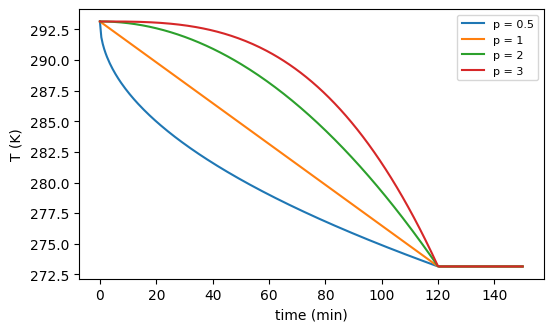

      p = 0.5   p = 1   p = 2   p = 3
d10     93.24  114.45  120.71  118.16
d50    153.86  221.16  241.05  241.26
d90    273.96  317.94  328.05  328.22
span     1.17    0.92    0.86    0.87


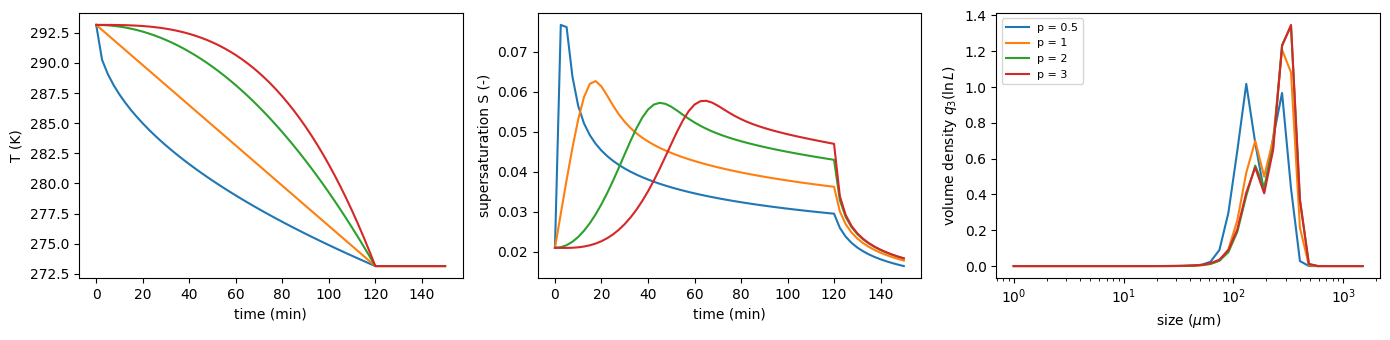

best p = 2.47, d50 = 241.9 um (9 simulations, 14 s)


In [6]:
def power_profile(p):
    return lambda t: TF + (T0 - TF) * (1 - min(t / T_COOL, 1.0)**p)


plot_profiles({'p = %g' % p: power_profile(p) for p in [0.5, 1, 2, 3]}, T_COOL + T_HOLD)

runs = {'p = %g' % p: run_batch(power_profile(p)) for p in [0.5, 1, 2, 3]}
print(pd.DataFrame({label: kpis_of(run) for label, run in runs.items()}).round(2))
plot_batches(runs)

tic = time.perf_counter()
best_p = minimize_scalar(lambda p: -kpis_of(run_batch(power_profile(p)))['d50'], bounds=(0.3, 4), method='bounded', options={'xatol': 0.05, 'maxiter': 12})  # [blank] bounded 1-D minimization of -d50 over 0.3 <= p <= 4 (minimize_scalar, method='bounded', options={'xatol': 0.05, 'maxiter': 12})
print('best p = %.2f, d50 = %.1f um (%i simulations, %.0f s)'
      % (best_p.x, -best_p.fun, best_p.nfev, time.perf_counter() - tic))

---
# Part 3 — Unguided: let the optimizer shape the profile

The power law is only one family. Now give the optimizer a **free cooling profile**: piecewise linear between knots at $t_k = 0, 30, 60, 90, 120$ min, with $T(t_0) = T_0$ and $T(t_4) = T_f$ fixed (so the yield is fixed), and the three interior temperatures $T_1, T_2, T_3$ free. The profile must never heat up:

$$ T_0 \ge T_1 \ge T_2 \ge T_3 \ge T_f $$

A convenient unconstrained parametrization: $z \in \mathbb{R}^3$, weights $w = \exp([z_1, z_2, z_3, 0])$, and each of the four segments takes the fraction $w_k / \sum w$ of the total temperature drop:

$$ T_k = T_0 - (T_0 - T_f) \frac{\sum_{i \le k} w_i}{\sum_{i=1}^4 w_i}, \qquad k = 1, 2, 3 $$

Every $z$ gives a feasible profile, and $z = 0$ is linear cooling. Keep the seed loading at 1 %.

**Tasks.** Find the profile that

* **(a)** maximizes $d_{50}$;
* **(b)** minimizes $d_{50}$ (e.g. fine particles for a fast-dissolving product);
* **(c)** minimizes the span without losing size, i.e. with $d_{50}$ at least that of linear cooling, $d_{50}^{lin}$. Use a penalty:

$$ \min_z \; \mathrm{span}(z) + 100 \max\left(0, \frac{d_{50}^{lin} - d_{50}(z)}{d_{50}^{lin}}\right)^2 $$

Then compare the three profiles, their supersaturation and their CSDs with linear cooling.

**Syntax you need**
```python
t_knots = np.linspace(0, T_COOL, 5)                       # s: 0, 30, 60, 90, 120 min
temp_func = lambda t: np.interp(t, t_knots, T_knots)      # T_knots: the 5 knot temperatures (K)
cryst = run_batch(temp_func)                              # your function from Part 2
kpis_of(cryst)['d50'], kpis_of(cryst)['span']
minimize(f, np.zeros(3), method='Nelder-Mead',
         options={'maxfev': 20, 'initial_simplex': [[0, 0, 0], [1.5, 0, 0], [0, 1.5, 0], [0, 0, 1.5]]})
```
Plotting helpers: `plot_profiles({label: temp_func, ...}, t_end)` and `plot_batches({label: cryst, ...})`.

**Budget.** A simulation takes 1-4 s, so 20 evaluations is about a minute per optimization. Some profiles cool very fast and can make the simulation fail: wrap it in `try/except` and return a large objective value.

In [7]:
# [blank-start] your code: the profile parametrization and an objective factory
T_KNOTS_TIME = np.linspace(0, T_COOL, 5)


def knot_temperatures(z):
    w = np.exp(np.append(z, 0.0))
    frac = np.cumsum(w)[:3] / w.sum()
    return np.concatenate([[T0], T0 - (T0 - TF) * frac, [TF]])


def profile(z):
    T_knots = knot_temperatures(z)
    return lambda t: np.interp(t, T_KNOTS_TIME, T_knots)


def evaluate_profile(z):
    try:
        return kpis_of(run_batch(profile(z)))
    except Exception as err:
        print('simulation failed at z =', np.round(z, 2), type(err).__name__)
        return None


def optimize(cost, z0=np.zeros(3), maxfev=20):
    """Minimize cost(kpis) over z with Nelder-Mead; returns the best z found and the history."""
    history = []

    def objective(z):
        kpis = evaluate_profile(z)
        value = 1e3 if kpis is None or not np.isfinite(cost(kpis)) else cost(kpis)
        history.append({'z': np.array(z), 'value': value, **(kpis or {})})
        return value

    simplex = [z0] + [z0 + 1.5 * np.eye(3)[k] for k in range(3)]
    tic = time.perf_counter()
    minimize(objective, z0, method='Nelder-Mead', options={'maxfev': maxfev, 'initial_simplex': simplex})
    history = pd.DataFrame(history)
    best = history.loc[history['value'].idxmin()]
    print('best value %.3f after %i simulations (%.0f s), knots %s K'
          % (best['value'], len(history), time.perf_counter() - tic, np.round(knot_temperatures(best['z']), 1)))
    return best['z'], history


linear = kpis_of(run_batch(profile(np.zeros(3))))
d50_lin = linear['d50']
print('linear cooling:', {key: round(val, 2) for key, val in linear.items()})
# [blank-end]

linear cooling: {'d10': np.float64(114.45), 'd50': np.float64(221.16), 'd90': np.float64(317.94), 'span': np.float64(0.92)}


In [8]:
# [blank-start] your code: (a) maximize d50
z_max, hist_max = optimize(lambda kpis: -kpis['d50'])
# [blank-end]

best value -249.427 after 20 simulations (39 s), knots [293.2 291.5 289.8 275.4 273.2] K


In [9]:
# [blank-start] your code: (b) minimize d50
z_min, hist_min = optimize(lambda kpis: kpis['d50'])
# [blank-end]

c:\Users\zhillma\AppData\Local\anaconda3\envs\pharmNew\Lib\site-packages\scipy\integrate\_ivp\bdf.py:416: RuntimeWarning: invalid value encountered in subtract
  D[order + 2] = d - D[order + 1]


best value 147.781 after 20 simulations (34 s), knots [293.2 273.2 273.2 273.2 273.2] K


In [10]:
# [blank-start] your code: (c) minimize the span with d50 >= d50 of linear cooling
z_span, hist_span = optimize(lambda kpis: kpis['span'] + 100 * max(0.0, (d50_lin - kpis['d50']) / d50_lin)**2)
# [blank-end]

best value 0.831 after 20 simulations (43 s), knots [293.2 290.9 288.9 276.5 273.2] K


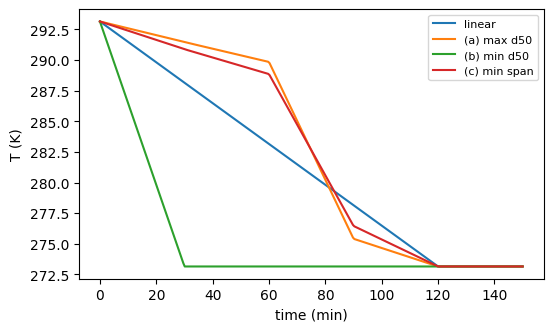

      linear  (a) max d50  (b) min d50  (c) min span
d10   114.45       110.84        88.08        125.65
d50   221.16       249.43       147.78        247.15
d90   317.94       332.05       272.83        331.15
span    0.92         0.89         1.25          0.83


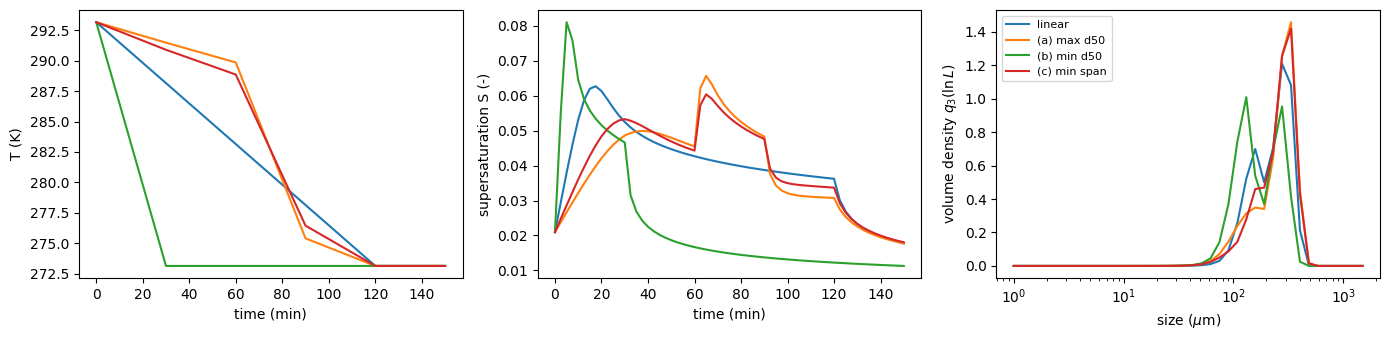

In [11]:
# [blank-start] your code: compare the profiles, their supersaturation and their CSDs
designs = {'linear': np.zeros(3), '(a) max d50': z_max, '(b) min d50': z_min, '(c) min span': z_span}
plot_profiles({label: profile(z) for label, z in designs.items()}, T_COOL + T_HOLD)
final_runs = {label: run_batch(profile(z)) for label, z in designs.items()}
print(pd.DataFrame({label: kpis_of(run) for label, run in final_runs.items()}).round(2))
plot_batches(final_runs)
# [blank-end]

---
## Questions to think about

**1.** Compare the supersaturation of profiles (a) and (b). Which one looks like "crash cooling", and why does it give small crystals with these kinetics?

<!-- [answer] -->
**Model answer.** Profile (b) drops the temperature early, so the supersaturation peaks high at the start, before the seeds have enough surface to consume it. Because nucleation is much more sensitive to supersaturation than growth ($b \approx 8.3$ vs $g \approx 4.5$), that peak produces a burst of nuclei; the solute is then shared among many crystals and $d_{50}$ is small (and the CSD is bimodal: grown seeds plus fines). Profile (a) does the opposite: it cools slowly while the seed surface is small and keeps $S$ low, so the solute goes onto the seeds.

**2.** Is the max-$d_{50}$ profile close to "constant supersaturation", a common heuristic? Why does a good profile cool slowly at first and faster later?

<!-- [answer] -->
**Model answer.** Roughly: the optimal profile keeps $S$ low and fairly flat instead of letting it peak. The rate at which crystals can absorb solute is proportional to their surface, which is small at the start (only the seeds) and grows as they grow. So the cooling rate, which generates supersaturation, should start slow and increase with the available surface, which is the shape of the optimum (similar to the "cubic" profile with $p > 1$). It is not exactly constant $S$, because the objective is $d_{50}$, not $S$; the hold time and the fixed end temperature also shape the end of the profile.

**3.** Re-run task (a) from a different starting point, e.g. `z0 = np.array([2.0, 2.0, 2.0])`. Do you get the same profile and $d_{50}$? What does that say about the optimization landscape and about a budget of 20 evaluations?

In [12]:
# [blank-start] your code
z_max2, _ = optimize(lambda kpis: -kpis['d50'], z0=np.array([2.0, 2.0, 2.0]))
print('d50 from z0 = 0: %.1f um, from z0 = 2: %.1f um' % (kpis_of(run_batch(profile(z_max)))['d50'],
                                                           kpis_of(run_batch(profile(z_max2)))['d50']))
# [blank-end]

c:\Users\zhillma\AppData\Local\anaconda3\envs\pharmNew\Lib\site-packages\scipy\integrate\_ivp\bdf.py:416: RuntimeWarning: invalid value encountered in subtract
  D[order + 2] = d - D[order + 1]


best value -246.398 after 20 simulations (41 s), knots [293.2 291.5 290.3 273.4 273.2] K


d50 from z0 = 0: 249.4 um, from z0 = 2: 246.4 um


<!-- [answer] -->
**Model answer.** Usually not exactly the same: Nelder-Mead with 20 evaluations stops near, not at, a local optimum, and the landscape is flat in some directions (several profiles give almost the same $d_{50}$), so different starts end at different knots with similar objective values. In practice: use several starts or a better optimizer (gradients from sensitivities), and be careful when interpreting small differences, which may be within the resolution of the 40-cell grid.

**4.** Robustness. The growth constant $k_g$ is uncertain by ±20 %. Re-simulate linear cooling and your profile (a) with `kg_factor = 0.8` and `1.2` (`run_batch(temp_func, kg_factor=...)`). Is the advantage of (a) over linear cooling robust? What would you do if it were not?

In [13]:
# [blank-start] your code
robust = {}
for kg_factor in [0.8, 1.0, 1.2]:
    robust['kg x %.1f' % kg_factor] = {
        'linear d50': kpis_of(run_batch(profile(np.zeros(3)), kg_factor=kg_factor))['d50'],
        '(a) d50': kpis_of(run_batch(profile(z_max), kg_factor=kg_factor))['d50']}
print(pd.DataFrame(robust).round(1))
# [blank-end]

            kg x 0.8  kg x 1.0  kg x 1.2
linear d50     196.7     221.2     237.9
(a) d50        233.1     249.4     262.4


<!-- [answer] -->
**Model answer.** Compare the gain of (a) over linear cooling at each `kg_factor`. In our runs the ranking does not change: (a) stays ahead over the ±20 % range, although the absolute $d_{50}$ shifts with $k_g$. If the advantage disappeared for some plausible $k_g$, you would optimize for robustness: maximize the worst case or the expected $d_{50}$ over a few $k_g$ scenarios, or (closer to MPC) measure the CSD or the concentration on line and re-optimize the remaining profile during the batch (shrinking-horizon control).

---
## If you finish early

* Make the seed loading a fourth decision variable (bounded between 0.5 and 10 %). Is a better profile or more seed the stronger lever? How do the optima of (a) and (c) change?
* Switch on secondary nucleation, `run_batch(..., nucl_sec=(5e12, 0, 2, 1))`, and re-optimize (c). Can the profile still give a narrow CSD?
* Check the optimum of (a) on a finer grid (`X_GRID = np.geomspace(1, 1500, 80)`, then re-run). Which differences between profiles survive?